# Turtle Breakout 15 — the turtle on every S&P 500 stock, each stock in its own account

Pre-registration: `discussions/Turtle_Breakout/017_claude_tb15_preregistration.md`. Code: `turtle_stock_accounts.py`, `turtle_stocks.py`; data: TB 14's Yahoo file.

Per stock, one account with exactly the TB 01 rules: **2% of the account's high-water mark per trade**, notional ≤ 3× equity; long only (TB 01) and long + reverse (TB 07). Daily bars, sessions as consecutive days, O→H→L→C fills; 5 bp per side; borrow 0.5%/yr on shorts. Each stock from 2000 (or its first session) + 30 sessions.
**G1** timing edge: pooled mean net R of the real longs vs random-entry longs with the same exits (50 runs), z-test p < 0.025 **and** difference ≥ 0.10R. **G2** reversal: stocks with Calmar(long + reverse) > Calmar(long), sign test p < 0.025.

Environment: `TB14_DATA` (default `<parent of DERIBIT_DATA_ROOT>/Stocks/tb14/stocks_daily.parquet`, downloaded if missing), `TB15_SYNTHETIC=1`.

In [1]:
import os, sys, json, gc, time, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_sizing as ts, turtle_reverse as tr, turtle_portfolio as tp, turtle_stocks as tk, turtle_stock_accounts as ta

SYNTHETIC = os.getenv('TB15_SYNTHETIC', '0') == '1'
AP = ta.AParams()
P = replace(tb.Params(), min_bar_share=0.0, funding=False, fee=AP.side_cost - tb.Params().slip)       # risk_frac 0.02, max_pos_lev 3 (TB 01)
RP = replace(tr.RParams(), side_cost=AP.side_cost)
SECTOR = pd.read_csv(ROOT / 'notebooks' / 'Turtle_Breakout' / '14' / '14_constituents_thesis.csv')
SECTOR = dict(zip(SECTOR.Symbol.astype(str).str.replace('.', '-', regex=False), SECTOR['GICS Sector']))
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb15-')) / '15'; AP = ta.AParams(n_null=10)
    rows = []
    for i in range(12):
        d, ses = tk.synthetic_daily(2600, seed=40 + i, drift=0.0002)
        rows.append(d.assign(ticker=f'S{i}').rename_axis('date').reset_index())
    for t in tk.INDEX_ETFS:
        d, ses = tk.synthetic_daily(2600, seed=hash(t) % 1000, drift=0.0003); rows.append(d.assign(ticker=t).rename_axis('date').reset_index())
    RAW = pd.concat(rows, ignore_index=True)
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '15'
    root = Path(os.environ['DERIBIT_DATA_ROOT']).parent
    DATA_FILE = Path(os.environ.get('TB14_DATA', str(root / 'Stocks' / 'tb14' / 'stocks_daily.parquet')))
    if not DATA_FILE.exists():
        sys.path.insert(0, str(ROOT / 'tools')); import download_tb14_stocks as dl
        DATA_FILE = dl.download(DATA_FILE.parent)
    RAW = pd.read_parquet(DATA_FILE)
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
for t in ('test_turtle_stock_accounts.py', 'test_turtle_stocks.py'):
    chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', t], cwd=str(ROOT), env=env, capture_output=True, text=True)
    print(t, chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
RAW['date'] = pd.to_datetime(RAW['date']).dt.tz_localize(None).dt.normalize()
RAW = RAW[RAW.date >= pd.Timestamp('2000-01-03')]
SES = pd.DatetimeIndex(sorted(RAW.loc[RAW.ticker == 'SPY', 'date'].unique()))
print('sessions', SES[0].date(), '->', SES[-1].date(), '| tickers', RAW.ticker.nunique())
print(json.dumps(ta.registration(AP), indent=1))

test_turtle_stock_accounts.py OK
test_turtle_stocks.py OK
sessions 2000-01-03 -> 2026-10-23 | tickers 506
{
 "risk_frac": 0.02,
 "pos_cap": 3.0,
 "size_base": "hwm",
 "side_cost": 0.0005,
 "borrow": 0.005,
 "n_null": 50,
 "min_effect_R": 0.1,
 "alpha": 0.05,
 "n_tests": 2,
 "seed": 20261027,
 "status": "PREREGISTERED_TB017",
 "version": "TB15-0.1.0",
 "rules": "TB 01 per stock: 2% of HWM per trade, 3x notional cap; reverse = TB 07",
 "gates": {
  "G1": "pooled mean R of real longs > random-entry longs (50 runs, z-test, p < alpha/2) and difference >= 0.10R",
  "G2": "stocks with Calmar(long_rev) > Calmar(long): sign test p < alpha/2"
 },
 "reported": [
  "per stock CAGR, max DD, Calmar, Sharpe, ruin for long, long + reverse, buy and hold",
  "share of stocks with positive CAGR; beating buy and hold on Calmar",
  "mean R of reverse trades",
  "by GICS sector",
  "per-stock timing edge sign test",
  "1% risk"
 ]
}


## 1. Every stock in its own account (plus the 4 index ETFs, reported)

In [2]:
ROWS, CURVES = [], {'long': {}, 'long_rev': {}, 'hold': {}}
NULL_SUM = np.zeros(AP.n_null); NULL_N = np.zeros(AP.n_null); REAL_SUM = 0.0; REAL_N = 0
rng = np.random.default_rng(AP.seed); T0 = time.time()
names = sorted(set(RAW.ticker) - set(tk.INDEX_ETFS)) + list(tk.INDEX_ETFS)
for n_, t in enumerate(names):
    grp = 'index' if t in tk.INDEX_ETFS else 'sp500'
    d = RAW[RAW.ticker == t].set_index('date')[['open', 'high', 'low', 'close']].sort_index()
    d = d[~d.index.duplicated()]
    if len(d) < 90:
        ROWS.append({'ticker': t, 'group': grp, 'status': 'too short'}); continue
    D = tb.prepare_asset(t, tk.pseudo_bars(d, SES), None, P)
    start = D.end[0] + pd.Timedelta(days=30)
    L0 = ts.trade_list(D, P, start, RP, with_reverse=False)
    if not len(L0):
        ROWS.append({'ticker': t, 'group': grp, 'status': 'no trades'}); continue
    L1 = ta.borrow_list(ts.trade_list(D, P, start, RP, with_reverse=True), D, AP.borrow, SES)
    a, _, sa = ta.account(D, L0, P, AP, start, SES); b, _, sb = ta.account(D, L1, P, AP, start, SES)
    first = a.index[0]; c = d.close[d.index >= first]; h = P.start_equity * c / c.iloc[0]
    CURVES['long'][t], CURVES['long_rev'][t], CURVES['hold'][t] = a, b, h
    ma, mb, mh = tk.metrics(a, P.start_equity), tk.metrics(b, P.start_equity), tk.metrics(h, P.start_equity)
    Rl = ta.trade_R(L0[~L0.end], D); R1 = ta.trade_R(L1, D); Rr = R1[(L1.dir == -1).to_numpy()]
    _, T, st = tb.simulate({t: D}, P, start=start)
    nul = ta.random_long_R(D, P, start, st['p_entry'][t], AP.n_null, rng)
    if grp == 'sp500':
        REAL_SUM += Rl.sum(); REAL_N += len(Rl); NULL_SUM += nul[:, 0]; NULL_N += nul[:, 1]
    row = {'ticker': t, 'group': grp, 'status': 'ok', 'sector': SECTOR.get(t, 'ETF' if grp == 'index' else '?'), 'first': first.date(), 'years': ma['years'],
           'longs': len(Rl), 'reverses': len(Rr), 'mean_R_long': Rl.mean(), 'mean_R_reverse': Rr.mean() if len(Rr) else np.nan,
           'null_mean_R': nul[:, 0].sum() / max(nul[:, 1].sum(), 1), 'win_rate_long': (Rl > 0).mean()}
    for pre, m in (('L', ma), ('LR', mb), ('BH', mh)):
        row.update({f'{pre}_cagr': m['cagr'], f'{pre}_max_dd': m['max_dd'], f'{pre}_calmar': m['calmar'], f'{pre}_sharpe': m['sharpe'], f'{pre}_ruined': m['ruined']})
    row.update({'L_mean_gross': sa['mean_gross_leverage'], 'L_max_gross': sa['max_gross_leverage']})
    ROWS.append(row)
    if n_ % 50 == 0:
        print(f'{n_}/{len(names)} {t}  ({time.time() - T0:.0f}s)', flush=True)
    del D; gc.collect()
TAB = pd.DataFrame(ROWS); OK = TAB[TAB.status == 'ok']; SPX = OK[OK.group == 'sp500']
print(TAB.status.value_counts().to_dict(), f'{time.time() - T0:.0f}s')

0/506 A  (9s)
50/506 BA  (208s)
100/506 CNC  (408s)
150/506 EBAY  (600s)
200/506 GE  (803s)
250/506 IRM  (988s)
300/506 MDLZ  (1188s)
350/506 ORLY  (1386s)
400/506 SBUX  (1579s)
450/506 TXN  (1777s)
500/506 ZBRA  (1966s)
{'ok': 504, 'no trades': 1, 'too short': 1} 1986s


## 2. Decision

In [3]:
DEC = ta.decide(REAL_SUM, REAL_N, NULL_SUM, NULL_N, SPX.L_calmar.to_numpy(float), SPX.LR_calmar.to_numpy(float), AP)
print(json.dumps(DEC, indent=1, default=float))

{
 "real_mean_R": 0.11500089483860364,
 "real_trades": 76491,
 "null_mean_R": 0.09693524413233973,
 "diff_R": 0.01806565070626391,
 "null_sd": 0.003087924624447515,
 "z": 5.850418291701722,
 "p_G1": 2.45169148868863e-09,
 "G1": "FAIL",
 "stocks": 500,
 "reverse_better": 24,
 "p_G2": 1.0,
 "G2": "FAIL",
 "verdict": "NO_EDGE"
}


## 3. Reported: distributions across stocks, buy and hold, sectors, ETFs

In [4]:
q = lambda s: pd.Series({'p10': s.quantile(.1), 'p25': s.quantile(.25), 'median': s.median(), 'p75': s.quantile(.75), 'p90': s.quantile(.9), 'mean': s.mean()})
DIST = pd.concat({f'{pre}_{m}': q(SPX[f'{pre}_{m}']) for m in ('cagr', 'max_dd', 'calmar', 'sharpe') for pre in ('L', 'LR', 'BH')}, axis=1).T
display(DIST.round(3))
SUMM = pd.Series({
    'stocks': len(SPX), 'trades long': int(SPX.longs.sum()), 'trades reverse': int(SPX.reverses.sum()),
    'mean R long (pooled)': DEC['real_mean_R'], 'mean R random longs (pooled)': DEC['null_mean_R'],
    'mean R reverse (mean of stocks)': SPX.mean_R_reverse.mean(),
    'share long CAGR > 0': (SPX.L_cagr > 0).mean(), 'share long+rev CAGR > 0': (SPX.LR_cagr > 0).mean(),
    'share long Calmar > buy-and-hold': (SPX.L_calmar > SPX.BH_calmar).mean(), 'share long Sharpe > buy-and-hold': (SPX.L_sharpe > SPX.BH_sharpe).mean(),
    'share long+rev CAGR > long': (SPX.LR_cagr > SPX.L_cagr).mean(), 'share long+rev max DD shallower': (SPX.LR_max_dd > SPX.L_max_dd).mean(),
    'ruined long': int(SPX.L_ruined.sum()), 'ruined long+rev': int(SPX.LR_ruined.sum()),
    'share stocks real mean R > own null': (SPX.mean_R_long > SPX.null_mean_R).mean(),
    'p sign test (per stock timing)': ta.sign_test(int((SPX.mean_R_long > SPX.null_mean_R).sum()), int(SPX.mean_R_long.notna().sum())),
    'median mean gross leverage (long)': SPX.L_mean_gross.median()})
display(SUMM.to_frame('value'))
SECT = SPX.groupby('sector').agg(stocks=('ticker', 'size'), L_cagr=('L_cagr', 'median'), LR_cagr=('LR_cagr', 'median'), BH_cagr=('BH_cagr', 'median'),
                                 L_max_dd=('L_max_dd', 'median'), LR_max_dd=('LR_max_dd', 'median'), mean_R_long=('mean_R_long', 'mean'),
                                 mean_R_reverse=('mean_R_reverse', 'mean'), share_LR_better=('LR_calmar', lambda s: np.nan))
SECT['share_LR_better'] = SPX.assign(b=SPX.LR_calmar > SPX.L_calmar).groupby('sector').b.mean()
display(SECT.round(3))
print('Index ETFs (reported)'); display(OK[OK.group == 'index'][['ticker', 'longs', 'reverses', 'mean_R_long', 'mean_R_reverse', 'L_cagr', 'L_max_dd', 'LR_cagr', 'LR_max_dd', 'BH_cagr', 'BH_max_dd']].round(3))
# equal-weight average of the per-stock accounts (each stock 1/N of capital: reported, not a portfolio test)
POOL = {}
for v in ('long', 'long_rev', 'hold'):
    lr = tk.equal_weight_hold({t: CURVES[v][t] for t in SPX.ticker}); POOL[v] = P.start_equity * np.exp(lr.cumsum())
display(pd.DataFrame({v: tk.metrics(s, P.start_equity) for v, s in POOL.items()}).T.round(3))

,p10,p25,median,p75,p90,mean
L_cagr,-0.009,0.001,0.014,0.027,0.042,0.016
LR_cagr,-0.113,-0.032,-0.008,0.011,0.032,-0.025
BH_cagr,0.049,0.079,0.116,0.164,0.209,0.141
L_max_dd,-0.480,-0.377,-0.280,-0.218,-0.175,-0.311
LR_max_dd,-0.969,-0.796,-0.544,-0.382,-0.280,-0.583
BH_max_dd,-0.925,-0.836,-0.684,-0.567,-0.483,-0.694
L_calmar,-0.020,0.004,0.049,0.113,0.211,0.079
LR_calmar,-0.117,-0.046,-0.015,0.027,0.117,-0.008
BH_calmar,0.056,0.107,0.182,0.268,0.364,0.226
L_sharpe,-0.040,0.060,0.205,0.359,0.520,0.216


,value
stocks,500.000000
trades long,76491.000000
trades reverse,47166.000000
mean R long (pooled),0.115001
mean R random longs (pooled),0.096935
mean R reverse (mean of stocks),-0.229285
share long CAGR > 0,0.790000
share long+rev CAGR > 0,0.374000
share long Calmar > buy-and-hold,0.144000
share long Sharpe > buy-and-hold,0.070000


,stocks,L_cagr,LR_cagr,BH_cagr,L_max_dd,LR_max_dd,mean_R_long,mean_R_reverse,share_LR_better
sector,,,,,,,,,
Communication Services,22,0.016,-0.006,0.087,-0.238,-0.431,0.205,-0.243,0.000
Consumer Discretionary,47,0.019,-0.003,0.138,-0.265,-0.466,0.184,-0.191,0.064
Consumer Staples,34,0.002,-0.026,0.089,-0.327,-0.765,0.041,-0.219,0.088
Energy,21,0.015,-0.000,0.112,-0.258,-0.436,0.186,-0.156,0.095
Financials,76,0.016,-0.008,0.113,-0.300,-0.588,0.134,-0.234,0.039
Health Care,59,0.008,-0.015,0.126,-0.321,-0.597,0.080,-0.232,0.034
Industrials,82,0.016,-0.008,0.140,-0.249,-0.501,0.145,-0.251,0.037
Information Technology,73,0.016,0.001,0.126,-0.272,-0.461,0.257,-0.210,0.055
Materials,25,-0.001,-0.014,0.114,-0.311,-0.596,0.026,-0.212,0.080


Index ETFs (reported)


,ticker,longs,reverses,mean_R_long,mean_R_reverse,L_cagr,L_max_dd,LR_cagr,LR_max_dd,BH_cagr,BH_max_dd
502,SPY,162.0,82.0,0.308,-0.249,0.038,-0.155,0.022,-0.214,0.084,-0.552
503,QQQ,179.0,98.0,0.179,-0.332,0.024,-0.173,-0.001,-0.574,0.083,-0.830
504,DIA,182.0,97.0,0.195,-0.130,0.026,-0.140,0.015,-0.357,0.084,-0.519
505,IWM,163.0,86.0,0.137,-0.302,0.017,-0.190,-0.004,-0.342,0.079,-0.586


,cagr,max_dd,calmar,sharpe,vol,ruined,final_multiple,years
long,0.013603,-0.095093,0.143053,0.471682,0.029629,False,1.434091,26.683094
long_rev,-0.029024,-0.553582,-0.052429,-0.67851,0.042174,False,0.455709,26.683094
hold,0.118035,-0.581819,0.202873,0.661305,0.199125,False,19.63099,26.683094


## 4. Figures

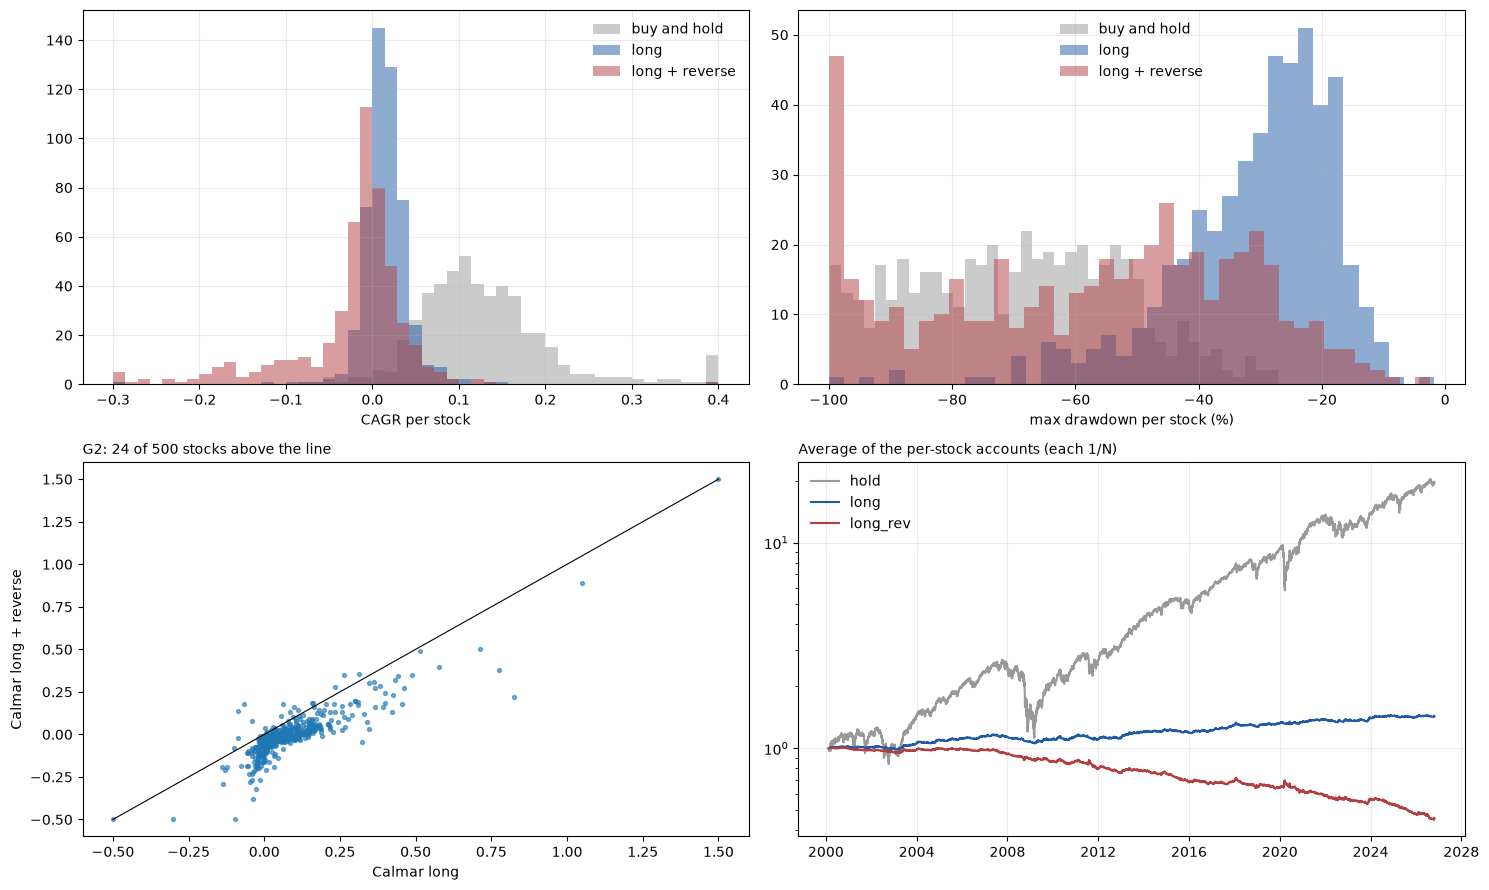

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
bins = np.linspace(-0.3, 0.4, 50)
for pre, col, lab in (('BH', '0.6', 'buy and hold'), ('L', '#1f5aa6', 'long'), ('LR', '#b33f40', 'long + reverse')):
    axes[0, 0].hist(SPX[f'{pre}_cagr'].clip(-0.3, 0.4), bins=bins, alpha=0.5, color=col, label=lab)
    axes[0, 1].hist(SPX[f'{pre}_max_dd'] * 100, bins=40, alpha=0.5, color=col, label=lab)
axes[0, 0].set_xlabel('CAGR per stock'); axes[0, 1].set_xlabel('max drawdown per stock (%)')
for a in axes[0]:
    a.legend(frameon=False); a.grid(alpha=0.25)
lim = (-0.5, 1.5)
axes[1, 0].scatter(SPX.L_calmar.clip(*lim), SPX.LR_calmar.clip(*lim), s=8, alpha=0.6)
axes[1, 0].plot(lim, lim, color='k', lw=0.8); axes[1, 0].set_xlabel('Calmar long'); axes[1, 0].set_ylabel('Calmar long + reverse')
axes[1, 0].set_title(f"G2: {DEC['reverse_better']} of {DEC['stocks']} stocks above the line", loc='left', fontsize=10)
for v, col in (('hold', '0.6'), ('long', '#1f5aa6'), ('long_rev', '#b33f40')):
    axes[1, 1].plot(POOL[v].index, POOL[v] / P.start_equity, color=col, label=v)
axes[1, 1].set_yscale('log'); axes[1, 1].legend(frameon=False); axes[1, 1].grid(alpha=0.25)
axes[1, 1].set_title('Average of the per-stock accounts (each 1/N)', loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Save

In [6]:
TAB.to_csv(OUT / '15_per_stock.csv', index=False); DIST.to_csv(OUT / '15_distributions.csv'); SUMM.to_csv(OUT / '15_summary.csv')
SECT.to_csv(OUT / '15_sectors.csv')
pd.DataFrame({v: s for v, s in POOL.items()}).to_csv(OUT / '15_average_of_accounts.csv')
np.savez(OUT / '15_null.npz', null_sum=NULL_SUM, null_n=NULL_N, real_sum=REAL_SUM, real_n=REAL_N)
(OUT / '15_decision.json').write_text(json.dumps({'decision': DEC, 'registration': ta.registration(AP), 'synthetic': SYNTHETIC}, indent=1, default=float))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '15_manifest.json').write_text(json.dumps({'version': ta.VERSION, 'stocks_version': tk.VERSION, 'git': git, 'python': platform.python_version(),
    'created_utc': pd.Timestamp.now('UTC').isoformat(), 'sessions': [str(SES[0].date()), str(SES[-1].date())], 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\15
VERDICT: NO_EDGE
